<a href="https://colab.research.google.com/github/moein-13/Breast_Cancer_Prediction/blob/main/Breast_Cancer_Prediction_(ML_ANN_Project).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.preprocessing import LabelEncoder , StandardScaler
from sklearn.model_selection import train_test_split

# Define column names from the UCI documentation
columns = [
    'id', 'diagnosis',
    'radius_mean', 'texture_mean', 'perimeter_mean', 'area_mean', 'smoothness_mean',
    'compactness_mean', 'concavity_mean', 'concave_points_mean', 'symmetry_mean', 'fractal_dimension_mean',
    'radius_se', 'texture_se', 'perimeter_se', 'area_se', 'smoothness_se',
    'compactness_se', 'concavity_se', 'concave_points_se', 'symmetry_se', 'fractal_dimension_se',
    'radius_worst', 'texture_worst', 'perimeter_worst', 'area_worst', 'smoothness_worst',
    'compactness_worst', 'concavity_worst', 'concave_points_worst', 'symmetry_worst', 'fractal_dimension_worst'
]

# Load the file
df = pd.read_csv('wdbc.data', header=None, names=columns)

df.head()

,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave_points_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave_points_worst,symmetry_worst,fractal_dimension_worst
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


In [ ]:
# Drop the identification number
df = df.drop(columns=['id'])

In [ ]:
df.sample(7)

,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave_points_mean,symmetry_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave_points_worst,symmetry_worst,fractal_dimension_worst
414,M,15.13,29.81,96.71,719.5,0.08320,0.04605,0.04686,0.02739,0.1852,...,17.26,36.91,110.10,931.4,0.1148,0.09866,0.1547,0.06575,0.3233,0.06165
209,B,15.27,12.91,98.17,725.5,0.08182,0.06230,0.05892,0.03157,0.1359,...,17.38,15.92,113.70,932.7,0.1222,0.21860,0.2962,0.10350,0.2320,0.07474
265,M,20.73,31.12,135.70,1419.0,0.09469,0.11430,0.13670,0.08646,0.1769,...,32.49,47.16,214.00,3432.0,0.1401,0.26440,0.3442,0.16590,0.2868,0.08218
469,B,11.62,18.18,76.38,408.8,0.11750,0.14830,0.10200,0.05564,0.1957,...,13.36,25.40,88.14,528.1,0.1780,0.28780,0.3186,0.14160,0.2660,0.09270
88,B,12.36,21.80,79.78,466.1,0.08772,0.09445,0.06015,0.03745,0.1930,...,13.83,30.50,91.46,574.7,0.1304,0.24630,0.2434,0.12050,0.2972,0.09261
92,B,13.27,14.76,84.74,551.7,0.07355,0.05055,0.03261,0.02648,0.1386,...,16.36,22.35,104.50,830.6,0.1006,0.12380,0.1350,0.10010,0.2027,0.06206
463,B,11.60,18.36,73.88,412.7,0.08508,0.05855,0.03367,0.01777,0.1516,...,12.77,24.02,82.68,495.1,0.1342,0.18080,0.1860,0.08288,0.3210,0.07863


In [ ]:
df.shape

(569, 31)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 31 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   diagnosis                569 non-null    object 
 1   radius_mean              569 non-null    float64
 2   texture_mean             569 non-null    float64
 3   perimeter_mean           569 non-null    float64
 4   area_mean                569 non-null    float64
 5   smoothness_mean          569 non-null    float64
 6   compactness_mean         569 non-null    float64
 7   concavity_mean           569 non-null    float64
 8   concave_points_mean      569 non-null    float64
 9   symmetry_mean            569 non-null    float64
 10  fractal_dimension_mean   569 non-null    float64
 11  radius_se                569 non-null    float64
 12  texture_se               569 non-null    float64
 13  perimeter_se             569 non-null    float64
 14  area_se                  5

In [ ]:
# encode the categorical target

label = LabelEncoder()
df['diagnosis'] = label.fit_transform(df['diagnosis'])

# separate features and targets

X = df.drop(columns=['diagnosis'])
y = df['diagnosis']

corr_matrix = X.corr().abs()

to_drop = []

for column_name in corr_matrix.columns:
    for row_name in corr_matrix.index:


        if corr_matrix.columns.get_loc(column_name) > corr_matrix.index.get_loc(row_name):

            correlation_value = corr_matrix.loc[row_name , column_name]

            if correlation_value > 0.90:
                if column_name not in to_drop:
                    to_drop.append(column_name)
                    print(f"Dropping '{column_name}' because it is highly correlated ({correlation_value:.2f}) with '{row_name}'")

print(f"/nTotal features dropped : {len(to_drop)}")
print(f"Features dropped : {to_drop}/n")
X_cleaned = X.drop(columns = to_drop)
print("Cleaning complete")


# Train test split ( 80 % train , 20 % test )

X_train , X_test , y_train , y_test  = train_test_split(X_cleaned , y , test_size = 0.2 , random_state = 42 , stratify= y)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)



Dropping 'perimeter_mean' because it is highly correlated (1.00) with 'radius_mean'
Dropping 'area_mean' because it is highly correlated (0.99) with 'radius_mean'
Dropping 'concave_points_mean' because it is highly correlated (0.92) with 'concavity_mean'
Dropping 'perimeter_se' because it is highly correlated (0.97) with 'radius_se'
Dropping 'area_se' because it is highly correlated (0.95) with 'radius_se'
Dropping 'radius_worst' because it is highly correlated (0.97) with 'radius_mean'
Dropping 'texture_worst' because it is highly correlated (0.91) with 'texture_mean'
Dropping 'perimeter_worst' because it is highly correlated (0.97) with 'radius_mean'
Dropping 'area_worst' because it is highly correlated (0.94) with 'radius_mean'
Dropping 'concave_points_worst' because it is highly correlated (0.91) with 'concave_points_mean'
/nTotal features dropped : 10
Features dropped : ['perimeter_mean', 'area_mean', 'concave_points_mean', 'perimeter_se', 'area_se', 'radius_worst', 'texture_worst

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score , classification_report , confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt


Model : Logistic Regression
Accuracy : 97.37%
Classification Report : 
              precision    recall  f1-score   support

           0       0.96      1.00      0.98        72
           1       1.00      0.93      0.96        42

    accuracy                           0.97       114
   macro avg       0.98      0.96      0.97       114
weighted avg       0.97      0.97      0.97       114



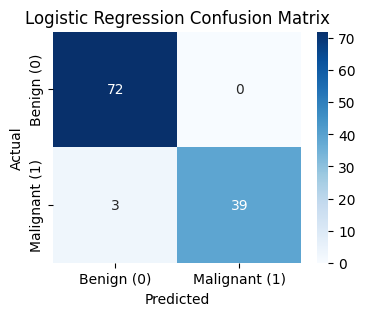



Model : Support Vector Machine
Accuracy : 97.37%
Classification Report : 
              precision    recall  f1-score   support

           0       0.97      0.99      0.98        72
           1       0.98      0.95      0.96        42

    accuracy                           0.97       114
   macro avg       0.97      0.97      0.97       114
weighted avg       0.97      0.97      0.97       114



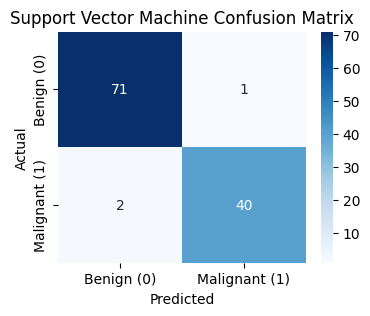



Model : Random Forest
Accuracy : 93.86%
Classification Report : 
              precision    recall  f1-score   support

           0       0.93      0.97      0.95        72
           1       0.95      0.88      0.91        42

    accuracy                           0.94       114
   macro avg       0.94      0.93      0.93       114
weighted avg       0.94      0.94      0.94       114



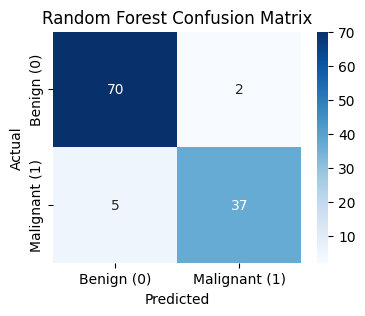

In [ ]:
log_reg = LogisticRegression(random_state = 42)
svm_model = SVC(random_state = 42)
rf_model = RandomForestClassifier(random_state = 42)

models = {
    'Logistic Regression' : log_reg,
    'Support Vector Machine' : svm_model,
    'Random Forest' : rf_model
}

ML_results = {}

for name , model in models.items():
  model.fit(X_train_scaled , y_train)
  y_pred = model.predict(X_test_scaled)

  accuracy = accuracy_score(y_test , y_pred)
  report = classification_report(y_test , y_pred)
  confusion = confusion_matrix(y_test , y_pred)

  ML_results[name] = {
      'Accuracy' : accuracy,
      'Classification Report' : report,
      'Confusion Matrix' : confusion
  }


for name , results in ML_results.items():
  print(f"Model : {name}")
  print(f"Accuracy : {results['Accuracy'] * 100:.2f}%")
  print(f"Classification Report : \n{results['Classification Report']}")


  plt.figure(figsize = (4,3))
  sns.heatmap(results['Confusion Matrix'], annot=True, fmt='d', cmap='Blues',
                xticklabels=['Benign (0)', 'Malignant (1)'],
                yticklabels=['Benign (0)', 'Malignant (1)'])
  plt.title(f'{name} Confusion Matrix')
  plt.ylabel('Actual')
  plt.xlabel('Predicted')
  plt.show()
  print("\n")




In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
from sklearn.metrics import accuracy_score , confusion_matrix , classification_report

In [ ]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device : {device}")

Using device : cuda


In [ ]:
#conversion numpy to tensors
X_train_tensor = torch.FloatTensor(X_train_scaled).to(device)
X_test_tensor = torch.FloatTensor(X_test_scaled).to(device)

y_train_tensor = torch.LongTensor(y_train.values).view(-1 , 1).to(device)
y_test_tensor = torch.LongTensor(y_test.values).view(-1 , 1 ).to(device)

print('Tensors created')

Tensors created


In [ ]:
# ANN architecture

class BreastCancerANN_Sequential(nn.Module):
  def __init__(self , input_dim):
    super(BreastCancerANN_Sequential , self).__init__()

    self.network = nn.Sequential(
        nn.Linear(input_dim , 16),
        nn.ReLU(),
        nn.Linear(16 , 8),
        nn.ReLU(),
        nn.Linear(8 , 1 ),
        nn.Sigmoid()

    )

  def forward( self , x ):
    return self.network(x)

input_dim = X_train_tensor.shape[1]
ann_model = BreastCancerANN_Sequential(input_dim).to(device)

print("ANN model created" , ann_model)

ANN model created BreastCancerANN_Sequential(
  (network): Sequential(
    (0): Linear(in_features=20, out_features=16, bias=True)
    (1): ReLU()
    (2): Linear(in_features=16, out_features=8, bias=True)
    (3): ReLU()
    (4): Linear(in_features=8, out_features=1, bias=True)
    (5): Sigmoid()
  )
)


In [ ]:
# loss function - binary cross entropy

criterion = nn.BCELoss()

optimizer = optim.Adam(ann_model.parameters() , lr = 0.01)
print("loss function and optimizer configured.")

loss function and optimizer configured.


Epoch [30/150], Loss: 0.0925
Epoch [60/150], Loss: 0.0364
Epoch [90/150], Loss: 0.0180
Epoch [120/150], Loss: 0.0063
Epoch [150/150], Loss: 0.0017


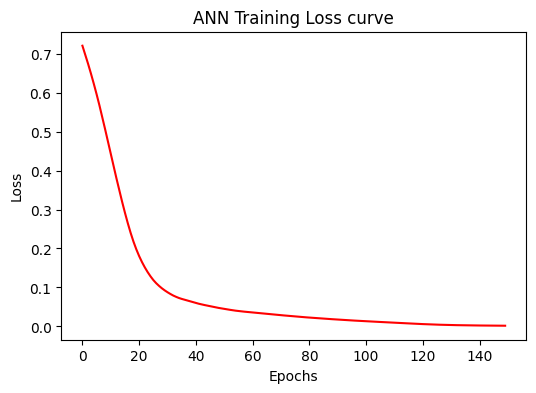

In [ ]:
# forward pass and backward pass

epochs = 150
train_losses = []


for epoch in range (epochs):
  ann_model.train()

  y_pred = ann_model(X_train_tensor)
  loss = criterion(y_pred , y_train_tensor.float())

  optimizer.zero_grad()
  loss.backward()
  optimizer.step()

  train_losses.append(loss.item())

  if( epoch + 1 ) % 30 == 0 :
    print(f'Epoch [{epoch+1}/{epochs}], Loss: {loss.item():.4f}')

plt.figure(figsize = (6,4))
plt.plot(train_losses , color = 'red')
plt.title('ANN Training Loss curve')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.show()

========== Deep Learning (ANN) Results ==========
Accuracy: 96.49%

Classification Report:
              precision    recall  f1-score   support

           0       0.95      1.00      0.97        72
           1       1.00      0.90      0.95        42

    accuracy                           0.96       114
   macro avg       0.97      0.95      0.96       114
weighted avg       0.97      0.96      0.96       114



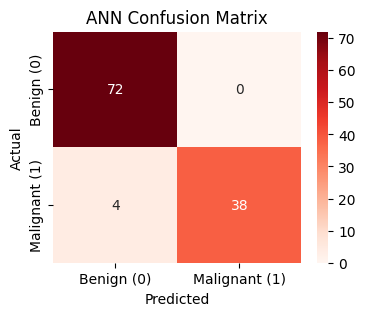

In [ ]:
# final comparison

ann_model.eval()   #for model evaluation mode

with torch.no_grad():
  y_test_pred_prob = ann_model(X_test_tensor)
  y_test_pred_class = y_test_pred_prob.round()

  y_test_pred_cpu = y_test_pred_class.cpu().numpy()
  y_test_cpu = y_test_tensor.cpu().numpy()

  ann_accuracy = accuracy_score(y_test_cpu , y_test_pred_cpu)
  ann_report = classification_report(y_test_cpu , y_test_pred_cpu)
  ann_confusion = confusion_matrix(y_test_cpu , y_test_pred_cpu)


  print("Deep Learning (ANN) Results ")
  print(f"Accuracy: {ann_accuracy * 100:.2f}%\n")
  print("Classification Report:")
  print(ann_report)

  plt.figure(figsize=(4, 3))
  sns.heatmap(ann_confusion, annot=True, fmt='d', cmap='Reds',
                xticklabels=['Benign (0)', 'Malignant (1)'],
                yticklabels=['Benign (0)', 'Malignant (1)'])

  plt.title('ANN Confusion Matrix')
  plt.ylabel('Actual')
  plt.xlabel('Predicted')
  plt.show()


